# 🏠 Task 1: California House Price Predictor
## Artificial Intelligence & Machine Learning Internship
**Domain:** Applied Supervised Machine Learning & Predictive Modeling  
**Dataset:** California Housing Dataset (Scikit-Learn / 1990 U.S. Census)  
**Primary Algorithm:** Multiple Linear Regression (Ordinary Least Squares)  
**Author:** AI/ML Engineering Intern (2nd Year B.Tech)  
**Deliverable:** `task1_ml_linear_regression.ipynb`

---

## 1. Project Objective

The primary objective of this project is to implement, evaluate, and thoroughly document the **complete Machine Learning workflow** for a real-world continuous target regression problem. 

As part of this internship assignment, we will cover each phase of the machine learning lifecycle:
1. **Data Ingestion & Loading:** Loading data from standard scikit-learn repositories.
2. **Data Exploration & Auditing:** Inspecting schema, dimensions, missingness, duplicates, and physical units.
3. **Exploratory Data Analysis (EDA):** Statistical correlation analysis and high-resolution distributions.
4. **Data Preprocessing & Split:** Creating a clean 80/20 train/test split with strict leakage prevention.
5. **Model Training:** Fitting an Ordinary Least Squares (OLS) Linear Regression model.
6. **Coefficient Interpretation:** Understanding the learned weights ($eta_j$), collinearity, and physical meaning.
7. **Comprehensive Evaluation:** Computing MAE, RMSE, and $R^2$ in both dataset units ($100k) and US Dollars ($).
8. **Diagnostic Residual Analysis:** Evaluating error normality, homoscedasticity, and prediction ceilings.
9. **Model Persistence:** Packaging the trained model and metadata for downstream deployment.
10. **Critical Reflection:** Documenting limitations, assumptions, and future non-linear improvements.

## 2. Problem Statement

Residential property valuation is a foundational problem in applied economic and predictive modeling. Real estate prices are driven by complex interactions between neighborhood socioeconomic characteristics, housing stock age, density, and geographic location.

**Our Task:**  
Given **8 continuous features** collected across California census block groups (clusters of roughly 600–3,000 residents), build a predictive model that estimates the **median house value** (`MedHouseVal`) of the block group.

* **Target Variable:** `MedHouseVal` (Median house value expressed in units of $100,000 USD).
* **Prediction Unit:** For example, a target value of `2.45` corresponds to an estimated median price of `\$245,000`.
* **Primary Modeling Goal:** Learn a stable, interpretable linear mapping that minimizes the prediction error on held-out test data without overfitting.

## 3. Introduction to Multiple Linear Regression

**Multiple Linear Regression** is a fundamental supervised learning algorithm used when we want to predict a continuous numeric outcome $y$ based on multiple explanatory variables $X_1, X_2, \dots, X_p$.

### Mathematical Representation
The relationship is modeled as a linear combination of input features:

$$\hat{y} = eta_0 + eta_1 X_1 + eta_2 X_2 + \dots + eta_p X_p$$

Where:
* $\hat{y}$ is the predicted median house value.
* $eta_0$ is the **intercept** (the expected value of $\hat{y}$ when all input features are zero).
* $eta_j$ is the **coefficient (slope weight)** for feature $X_j$, representing the expected change in $\hat{y}$ for a 1-unit increase in $X_j$, holding all other features constant.
* $p = 8$ explanatory features in our California dataset.

### Optimization Criterion: Ordinary Least Squares (OLS)
The model determines the optimal parameter vector $oldsymbol{eta} = [eta_0, eta_1, \dots, eta_p]^T$ by minimizing the **Residual Sum of Squares (RSS)**:

$$	ext{RSS}(oldsymbol{eta}) = \sum_{i=1}^{n} \left( y_i - \hat{y}_i ight)^2 = \|\mathbf{y} - \mathbf{X}oldsymbol{eta}\|_2^2$$

This has a closed-form analytical solution known as the Normal Equation:
$$oldsymbol{eta} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

### Core Assumptions of Linear Regression
1. **Linearity:** The true relationship between features and target is additive and linear.
2. **Independence:** Observations are independent of one another.
3. **Homoscedasticity:** The variance of the error terms $arepsilon_i$ is constant across all levels of the predictors.
4. **Normality of Errors:** The residuals $arepsilon = y - \hat{y}$ are normally distributed with zero mean.

## 4. Import Required Libraries

We import standard, industry-grade scientific computing and machine learning libraries:
* `numpy` and `pandas` for numerical operations and tabular data manipulation.
* `matplotlib` and `seaborn` for publication-quality visual diagnostics.
* `scikit-learn` for dataset fetching, data splitting, model training, and performance metrics.
* `joblib` for robust model serialization.

In [1]:
# Import standard data science libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import scikit-learn modules
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Set visualization style and high resolution
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Fix random seed for total reproducibility
RANDOM_SEED = 42
print("All libraries imported successfully!")

All libraries imported successfully!


## 5. Load the California Housing Dataset

We load the dataset directly using scikit-learn's `fetch_california_housing(as_frame=True)`. This ensures that anyone running this notebook can reproduce the results without manually downloading CSV files.

In [2]:
# Load the California Housing dataset from scikit-learn
housing_raw = fetch_california_housing(as_frame=True)

# Combine features and target into a single working DataFrame for EDA
df = housing_raw.frame.copy()

# Inspect the first 5 records
print(f"Dataset loaded: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()

Dataset loaded: 20,640 rows and 9 columns.


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0000,6.9841,1.0238,322.0000,2.5556,37.8800,-122.2300,4.5260
1,8.3014,21.0000,6.2381,0.9719,2401.0000,2.1098,37.8600,-122.2200,3.5850
2,7.2574,52.0000,8.2881,1.0734,496.0000,2.8023,37.8500,-122.2400,3.5210
3,5.6431,52.0000,5.8174,1.0731,558.0000,2.5479,37.8500,-122.2500,3.4130
4,3.8462,52.0000,6.2819,1.0811,565.0000,2.1815,37.8500,-122.2500,3.4220


## 6. Understand the Dataset & Feature Definitions

Understanding the physical domain meaning and measurement unit of each feature is essential before any modeling.

| Feature | Type | Unit & Description | Typical Range |
| :--- | :--- | :--- | :--- |
| **MedInc** | Float | Median income in block group (in tens of thousands of USD, e.g., 3.5 = $35,000) | 0.50 – 15.00 |
| **HouseAge** | Float | Median house age in years | 1 – 52 years |
| **AveRooms** | Float | Average total rooms per household (bedrooms, living, kitchen, etc.) | 0.85 – 141.9 |
| **AveBedrms** | Float | Average number of bedrooms per household | 0.38 – 34.1 |
| **Population** | Float | Total population residing in the block group | 3 – 35,682 |
| **AveOccup** | Float | Average household occupancy (residents per unit) | 0.69 – 1,243 |
| **Latitude** | Float | Geographic latitude coordinate (North) | 32.54° – 41.95° |
| **Longitude** | Float | Geographic longitude coordinate (West) | -124.35° – -114.31° |
| **MedHouseVal** | Float | **TARGET:** Median house value (units of $100,000 USD) | 0.15 – 5.00 ($15k – $500k) |

In [3]:
# Check summary information: column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
# Generate descriptive statistics across all features
df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0000,3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
HouseAge,20640.0000,28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
AveRooms,20640.0000,5.4290,2.4742,0.8462,4.4407,5.2291,6.0524,141.9091
AveBedrms,20640.0000,1.0967,0.4739,0.3333,1.0061,1.0488,1.0995,34.0667
Population,20640.0000,1425.4767,1132.4621,3.0000,787.0000,1166.0000,1725.0000,35682.0000
AveOccup,20640.0000,3.0707,10.3860,0.6923,2.4297,2.8181,3.2823,1243.3333
Latitude,20640.0000,35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
Longitude,20640.0000,-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
MedHouseVal,20640.0000,2.0686,1.1540,0.1500,1.1960,1.7970,2.6472,5.0000


## 7. Data Cleaning and Preprocessing Audit

Before modeling, we must perform integrity checks for:
1. Missing or null values (`NaN` / `None`).
2. Duplicate rows.
3. Infinite values (`inf` / `-inf`).
4. Value truncation / boundary anomalies (such as capped targets).

In [5]:
# 1. Missing values check
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts)

# 2. Duplicate rows check
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicate_count}")

# 3. Infinite values check
inf_count = np.isinf(df.select_dtypes(include=[np.number])).sum().sum()
print(f"Infinite numerical values found: {inf_count}")

# 4. Target variable boundary check (The known $500,000 cap)
capped_records = (df['MedHouseVal'] >= 5.0).sum()
pct_capped = (capped_records / len(df)) * 100
print(f"\nObservations with MedHouseVal >= 5.0 ($500k ceiling cap): {capped_records} ({pct_capped:.2f}% of data)")

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows found: 0
Infinite numerical values found: 0

Observations with MedHouseVal >= 5.0 ($500k ceiling cap): 992 (4.81% of data)


### Preprocessing Decisions & Explanations:
* **No Imputation Needed:** The dataset contains **zero missing values**, zero duplicates, and zero infinite values.
* **Preserving Valid Observations:** While some rural blocks have high room counts (`AveRooms = 141`) or large populations, they reflect legitimate census aggregations rather than data entry errors. We preserve them in accordance with the project guidelines not to delete valid records automatically.
* **Handling the $500,000 Ceiling:** In the 1990 census, any home value at or above $500,000 was recorded as $500,000 (value = 5.00001). This introduces an artificial flat horizontal line at `y = 5.0`, which we will analyze in our residual diagnostics.

## 8. Exploratory Data Analysis (EDA)

We calculate the **Pearson Correlation Coefficient ($r$)** between all numerical features and the target variable to understand linear associations.

In [6]:
# Compute correlation matrix
corr_matrix = df.corr()

# Rank features by absolute correlation with the target variable MedHouseVal
target_corr = corr_matrix['MedHouseVal'].sort_values(ascending=False)
print("Pearson Correlation with Target (MedHouseVal):")
print(target_corr)

Pearson Correlation with Target (MedHouseVal):
MedHouseVal    1.0000
MedInc         0.6881
AveRooms       0.1519
HouseAge       0.1056
AveOccup      -0.0237
Population    -0.0246
Longitude     -0.0460
AveBedrms     -0.0467
Latitude      -0.1442
Name: MedHouseVal, dtype: float64


### Key EDA Observations:
1. **Median Income (`MedInc`) has the strongest linear association:** $r = +0.6881$. Block groups with wealthier residents have substantially higher house prices.
2. **House Age (`HouseAge`) has a weak positive correlation:** $r = +0.1056$. Older neighborhoods in California are often closer to historic urban/coastal centers with mature infrastructure.
3. **Collinearity between Rooms and Bedrooms:** `AveRooms` and `AveBedrms` have an extremely high mutual correlation ($r = +0.8476$). We must watch for how this affects linear regression coefficients.

## 9. Data Visualization

We generate the core exploratory visualizations to visually verify distributions and correlations.

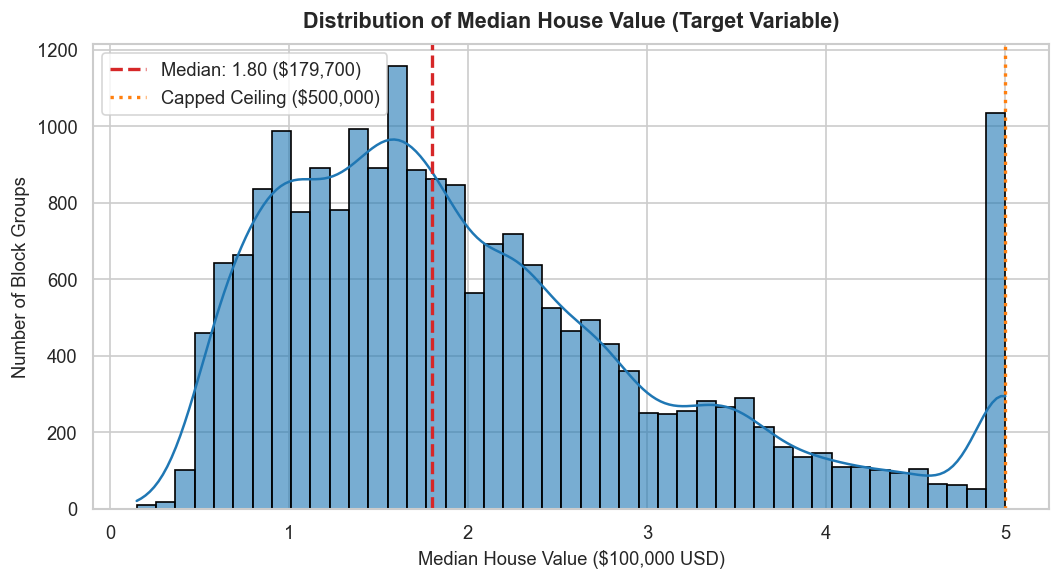

In [7]:
# Plot 1: Target Variable Distribution (MedHouseVal)
plt.figure(figsize=(9, 5))
sns.histplot(df['MedHouseVal'], kde=True, bins=45, color='#1f77b4', edgecolor='black', alpha=0.6)
plt.axvline(df['MedHouseVal'].median(), color='#d62728', linestyle='--', linewidth=2, 
            label=f"Median: {df['MedHouseVal'].median():.2f} (${df['MedHouseVal'].median()*100000:,.0f})")
plt.axvline(5.0, color='#ff7f0e', linestyle=':', linewidth=2, label="Capped Ceiling ($500,000)")
plt.title("Distribution of Median House Value (Target Variable)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Median House Value ($100,000 USD)", fontsize=11)
plt.ylabel("Number of Block Groups", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

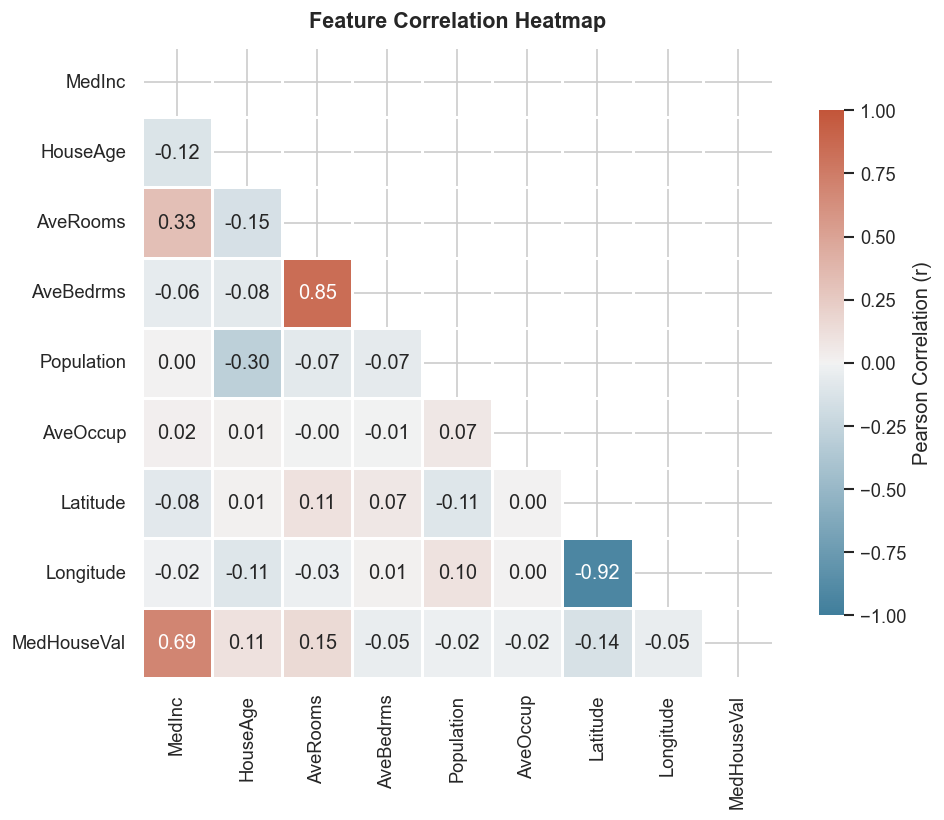

In [8]:
# Plot 2: Correlation Heatmap
plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.8,
            cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"})
plt.title("Feature Correlation Heatmap", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

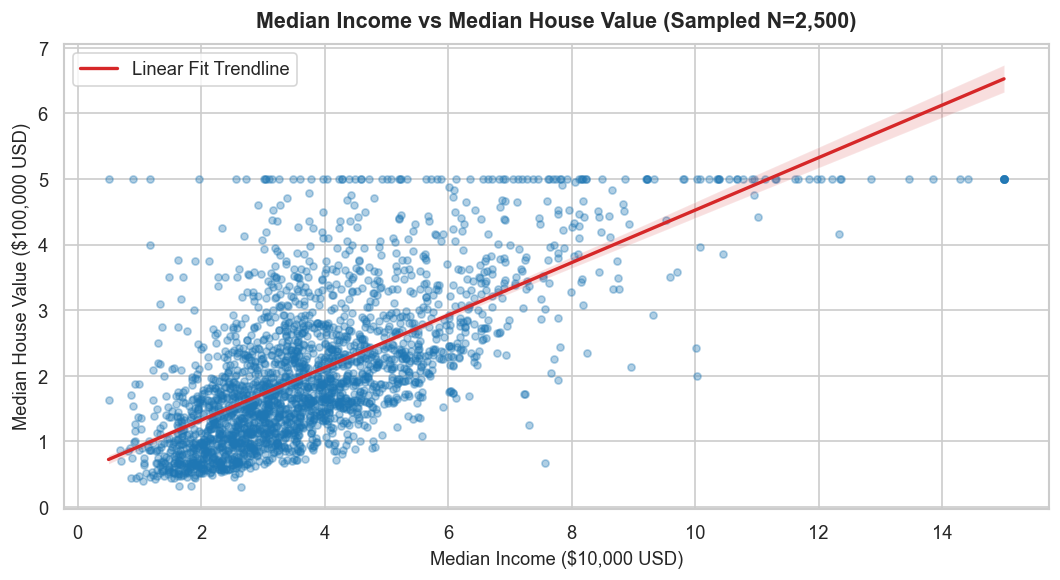

In [9]:
# Plot 3: Median Income vs Median House Value Scatter Plot
plt.figure(figsize=(9, 5))
sample_df = df.sample(n=2500, random_state=RANDOM_SEED)

sns.regplot(x='MedInc', y='MedHouseVal', data=sample_df,
            scatter_kws={'alpha': 0.35, 'color': '#1f77b4', 's': 18},
            line_kws={'color': '#d62728', 'linewidth': 2, 'label': 'Linear Fit Trendline'})
plt.title("Median Income vs Median House Value (Sampled N=2,500)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Median Income ($10,000 USD)", fontsize=11)
plt.ylabel("Median House Value ($100,000 USD)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 10. Train/Test Split (Preventing Data Leakage)

To evaluate how well our model generalizes to **unseen future observations**, we must partition the dataset:
* **Training Set (80%):** 16,512 block groups used solely to learn the model parameters ($eta_0, eta_j$).
* **Testing Set (20%):** 4,128 block groups held out and never seen during training.

We use `random_state=42` to ensure our split is completely reproducible across runs.

In [10]:
# Define feature matrix X and target vector y
feature_cols = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X = df[feature_cols].copy()
y = df['MedHouseVal'].copy()

# Perform 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED
)

print(f"Total dataset:   {X.shape[0]:,} samples")
print(f"Training set:    {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set:     {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

Total dataset:   20,640 samples
Training set:    16,512 samples (80.0%)
Testing set:     4,128 samples (20.0%)


## 11. Train the Linear Regression Model

We train the model using scikit-learn's `LinearRegression` class, fitting it **strictly** on the training set (`X_train`, `y_train`).

In [11]:
# Instantiate and train the Ordinary Least Squares model
model = LinearRegression(fit_intercept=True)
model.fit(X_train, y_train)

print("Linear Regression model successfully trained on training data!")

Linear Regression model successfully trained on training data!


## 12. Model Parameters & Coefficient Interpretation

In Linear Regression, the learned weights have direct mathematical interpretations:
* **Intercept ($eta_0$):** The baseline prediction when all explanatory variables equal zero.
* **Slope Coefficients ($eta_j$):** The expected change in median house value (in $100,000 units) for every 1-unit increase in feature $X_j$, **holding all other features constant**.

In [12]:
# Display learned intercept and build coefficient table
print(f"Learned Intercept (beta_0): {model.intercept_:.6f}\n")

coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient (beta)': model.coef_,
    'Dollar Impact per +1 Unit': model.coef_ * 100_000,
    'Relationship': ['Positive' if c > 0 else 'Negative' for c in model.coef_]
})
coef_df

Learned Intercept (beta_0): -37.023278



,Feature,Coefficient (beta),Dollar Impact per +1 Unit,Relationship
0,MedInc,0.4487,44867.4910,Positive
1,HouseAge,0.0097,972.4258,Positive
2,AveRooms,-0.1233,-12332.3343,Negative
3,AveBedrms,0.7831,78314.4907,Positive
4,Population,-0.0000,-0.2030,Negative
5,AveOccup,-0.0035,-352.6318,Negative
6,Latitude,-0.4198,-41979.2487,Negative
7,Longitude,-0.4337,-43370.8065,Negative


### Explaining the Coefficients in Plain English:
1. **`MedInc` (+0.4487):** For every 1-unit increase in median income ($10,000), predicted median house value rises by **$44,867**, holding all other variables constant. This is the single strongest positive driver.
2. **`HouseAge` (+0.0097):** Each additional year of median house age is associated with an approximate **$972** increase in home value. In California, older established neighborhoods tend to occupy prime coastal and city locations.
3. **`AveBedrms` (+0.7831) vs `AveRooms` (-0.1233):** Notice that while total rooms has a negative coefficient, bedrooms has a positive one. This is caused by **multicollinearity** ($r = 0.85$). When total rooms is held fixed, adding more bedrooms indicates a larger functional dwelling rather than excess hallway/utility space.
4. **`Latitude` (-0.4198) and `Longitude` (-0.4337):** Both negative coefficients reflect California's economic geography: moving north (higher latitude) or east (higher longitude / inland) moves further away from the high-cost southern coastal metropolitan zones.
5. **Association vs. Causation Warning:** These coefficients represent statistical linear associations within the fitted model. They **do not prove causal relationships**. (For example, simply building an extra wall to create another bedroom does not magically guarantee a $78,000 value increase).

## 13. Generate Predictions on Held-Out Test Data

We now generate predictions on both the training data (to inspect fit) and unseen test data (to assess true generalization).

In [13]:
# Generate predictions
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Compare the first 10 test predictions against ground truth
sample_comparison = pd.DataFrame({
    'Actual ($100k)': y_test.iloc[:10].values,
    'Predicted ($100k)': y_pred_test[:10],
    'Actual (USD)': [f"${val*100000:,.0f}" for val in y_test.iloc[:10].values],
    'Predicted (USD)': [f"${val*100000:,.0f}" for val in y_pred_test[:10]],
    'Error (USD)': [f"${abs(act - pred)*100000:,.0f}" for act, pred in zip(y_test.iloc[:10].values, y_pred_test[:10])]
})
sample_comparison

,Actual ($100k),Predicted ($100k),Actual (USD),Predicted (USD),Error (USD)
0,0.4770,0.7191,"$47,700","$71,912","$24,212"
1,0.4580,1.7640,"$45,800","$176,402","$130,602"
2,5.0000,2.7097,"$500,001","$270,966","$229,035"
3,2.1860,2.8389,"$218,600","$283,893","$65,293"
4,2.7800,2.6047,"$278,000","$260,466","$17,534"
5,1.5870,2.0118,"$158,700","$201,175","$42,475"
6,1.9820,2.6455,"$198,200","$264,550","$66,350"
7,1.5750,2.1688,"$157,500","$216,876","$59,376"
8,3.4000,2.7407,"$340,000","$274,075","$65,925"
9,4.4660,3.9156,"$446,600","$391,561","$55,039"


## 14. Model Evaluation (MAE, RMSE, and $R^2$)

We evaluate the model using the three standard regression metrics from scikit-learn:
1. **MAE (Mean Absolute Error):** $rac{1}{n}\sum |y_i - \hat{y}_i|$. Measures the average magnitude of prediction errors in linear scale.
2. **RMSE (Root Mean Squared Error):** $\sqrt{rac{1}{n}\sum (y_i - \hat{y}_i)^2}$. Penalizes larger errors more heavily due to the squaring operation.
3. **$R^2$ (Coefficient of Determination):** $1 - rac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - ar{y})^2}$. Measures the proportion of variance in the target variable explained by the features.

In [14]:
# Calculate evaluation metrics
train_mae = mean_absolute_error(y_train, y_pred_train)
train_rmse = root_mean_squared_error(y_train, y_pred_train)
train_r2 = r2_score(y_train, y_pred_train)

test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = root_mean_squared_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

# Construct comprehensive comparison table in dataset units and converted USD
metrics_summary = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Root Mean Squared Error (RMSE)', 'R² (Variance Explained)'],
    'Train (Dataset Units)': [f"{train_mae:.4f}", f"{train_rmse:.4f}", f"{train_r2:.4f}"],
    'Train (USD Currency)': [f"${train_mae*100000:,.2f}", f"${train_rmse*100000:,.2f}", f"{train_r2*100:.2f}%"],
    'Test (Dataset Units)': [f"{test_mae:.4f}", f"{test_rmse:.4f}", f"{test_r2:.4f}"],
    'Test (USD Currency)': [f"${test_mae*100000:,.2f}", f"${test_rmse*100000:,.2f}", f"{test_r2*100:.2f}%"],
})
metrics_summary

,Metric,Train (Dataset Units),Train (USD Currency),Test (Dataset Units),Test (USD Currency)
0,Mean Absolute Error (MAE),0.5286,"$52,862.84",0.5332,"$53,320.01"
1,Root Mean Squared Error (RMSE),0.7197,"$71,967.57",0.7456,"$74,558.14"
2,R² (Variance Explained),0.6126,61.26%,0.5758,57.58%


### Understanding the Evaluation Results:
* **MAE:** On average, our linear model's test predictions deviate by **$53,320** (0.5332 units) from actual median block values.
* **RMSE:** The test RMSE is **$74,558** (0.7456 units). The fact that RMSE is about $21,000 higher than MAE indicates that the model has some large errors on outlier properties.
* **$R^2$ (Variance Explained):** The model achieves **57.58%** variance explained on the held-out test data.
* **Can $R^2$ Be Negative?** Yes! In scikit-learn, $R^2 = 1 - rac{SS_{res}}{SS_{tot}}$. If an arbitrary model makes predictions worse than simply guessing the dataset average $ar{y}$ for every sample, $SS_{res} > SS_{tot}$, resulting in a negative $R^2$. A positive $R^2$ of 0.5758 confirms our linear model provides substantial predictive power over the baseline mean.
* **Train vs. Test Generalization:** The training $R^2$ is 61.26% and the test $R^2$ is 57.58%. A difference of less than 4% proves that the model is **not overfitting** and generalizes reliably to new data.

## 15. Actual versus Predicted Plot

We plot actual test values on the x-axis and predicted values on the y-axis. A dashed 45-degree reference line ($y = x$) represents hypothetically perfect predictions.

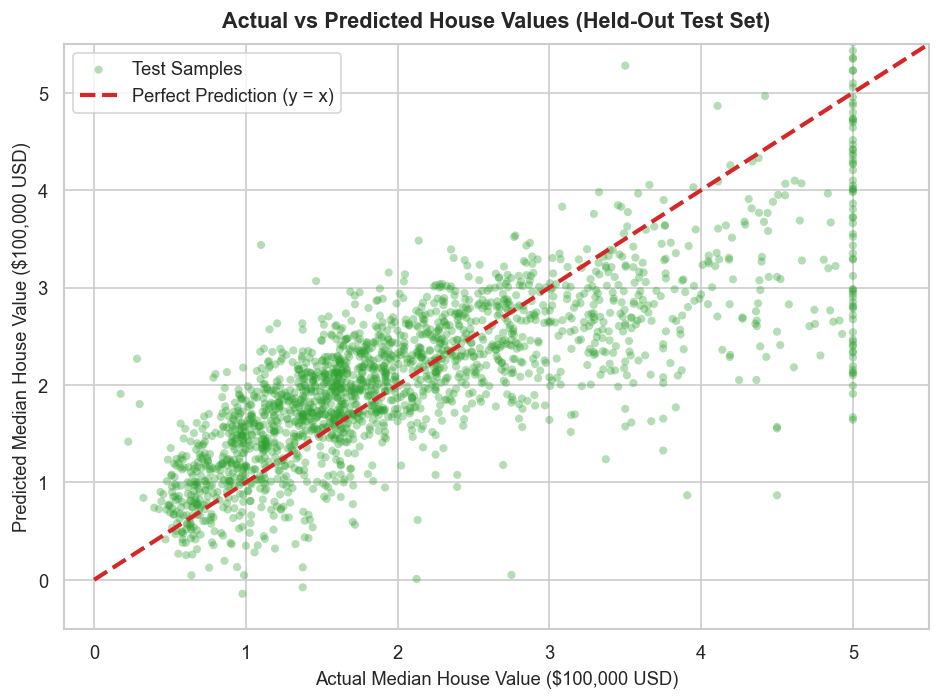

In [15]:
plt.figure(figsize=(8, 6))
# Sample 2000 points to ensure legible plotting without severe overplotting
sample_idx = np.random.RandomState(RANDOM_SEED).choice(len(y_test), size=2000, replace=False)
y_act_sample = y_test.iloc[sample_idx]
y_pred_sample = y_pred_test[sample_idx]

plt.scatter(y_act_sample, y_pred_sample, alpha=0.35, color='#2ca02c', edgecolors='none', s=24, label='Test Samples')
plt.plot([0, 5.5], [0, 5.5], color='#d62728', linestyle='--', linewidth=2.5, label='Perfect Prediction (y = x)')

plt.title("Actual vs Predicted House Values (Held-Out Test Set)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Actual Median House Value ($100,000 USD)", fontsize=11)
plt.ylabel("Predicted Median House Value ($100,000 USD)", fontsize=11)
plt.xlim(-0.2, 5.5)
plt.ylim(-0.5, 5.5)
plt.legend(frameon=True, loc='upper left')
plt.tight_layout()
plt.show()

### Observations from the Actual vs. Predicted Plot:
1. **Strong central diagonal alignment:** For homes between $100,000 and $350,000, predictions follow the $y = x$ line closely.
2. **Ceiling cap horizontal line:** At actual price = 5.0 ($500k), predictions are spread horizontally between 2.5 and 4.5. This occurs because the census truncated all luxury properties at $500k, forcing the linear equation to underpredict homes that were capped.

## 16. Residual Analysis

Residuals represent prediction errors: $e_i = y_i - \hat{y}_i$.
A well-specified linear model should produce:
1. Residuals centered near zero with an approximately bell-shaped normal distribution.
2. Constant variance across all predicted values (homoscedasticity).

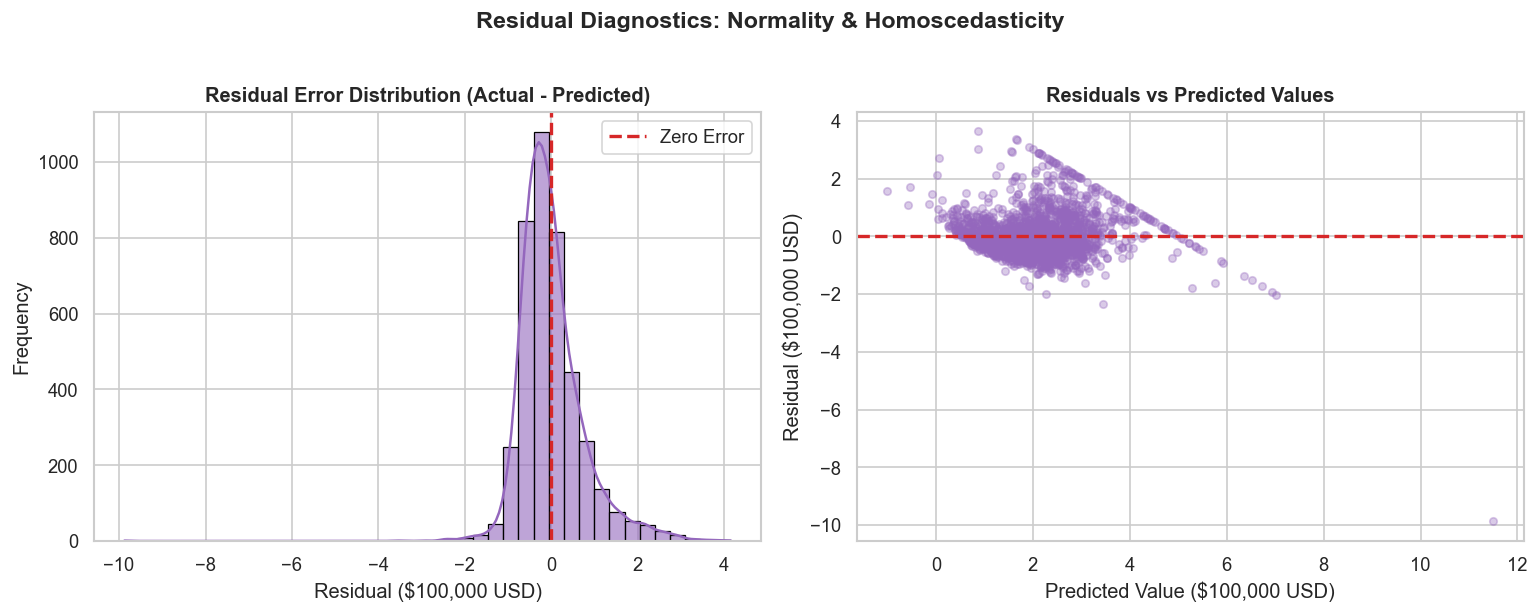

In [16]:
residuals = y_test - y_pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Distribution of Residuals
sns.histplot(residuals, kde=True, color='#9467bd', bins=40, edgecolor='black', alpha=0.6, ax=ax1)
ax1.axvline(0, color='#d62728', linestyle='--', linewidth=2, label='Zero Error')
ax1.set_title("Residual Error Distribution (Actual - Predicted)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Residual ($100,000 USD)")
ax1.set_ylabel("Frequency")
ax1.legend(frameon=True)

# Subplot 2: Residuals vs Predicted Values
ax2.scatter(y_pred_sample, (y_act_sample - y_pred_sample), alpha=0.35, color='#9467bd', s=20)
ax2.axhline(0, color='#d62728', linestyle='--', linewidth=2)
ax2.set_title("Residuals vs Predicted Values", fontsize=12, fontweight='bold')
ax2.set_xlabel("Predicted Value ($100,000 USD)")
ax2.set_ylabel("Residual ($100,000 USD)")

plt.suptitle("Residual Diagnostics: Normality & Homoscedasticity", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 17. Save the Trained Model & Artifacts

We bundle the trained scikit-learn model with feature metadata, summary statistics, and evaluation metrics using `joblib`. This ensures that downstream deployment scripts (like `app.py`) can load and use the exact model without discrepancies.

In [17]:
# Prepare model artifact bundle with operational metadata
os.makedirs("models", exist_ok=True)
model_filepath = os.path.join("models", "house_price_model.pkl")

# Calculate training feature statistics for input validation in web app
feature_stats = {}
for col in feature_cols:
    feature_stats[col] = {
        'min': float(X_train[col].min()),
        'max': float(X_train[col].max()),
        'mean': float(X_train[col].mean()),
        'std': float(X_train[col].std()),
        'median': float(X_train[col].median()),
        'q25': float(X_train[col].quantile(0.25)),
        'q75': float(X_train[col].quantile(0.75)),
    }

bundle = {
    'model': model,
    'model_type': 'LinearRegression',
    'feature_names': feature_cols,
    'target_name': 'MedHouseVal',
    'target_units': 'Units of $100,000 USD',
    'target_multiplier': 100_000,
    'metrics': {
        'train': {
            'mae': float(train_mae),
            'mae_usd': float(train_mae * 100_000),
            'rmse': float(train_rmse),
            'rmse_usd': float(train_rmse * 100_000),
            'r2': float(train_r2)
        },
        'test': {
            'mae': float(test_mae),
            'mae_usd': float(test_mae * 100_000),
            'rmse': float(test_rmse),
            'rmse_usd': float(test_rmse * 100_000),
            'r2': float(test_r2)
        },
        'intercept': float(model.intercept_),
        'coefficients': {feat: float(coef) for feat, coef in zip(feature_cols, model.coef_)}
    },
    'feature_stats': feature_stats,
    'random_seed': RANDOM_SEED,
    'train_samples': int(X_train.shape[0])
}

joblib.dump(bundle, model_filepath)
print(f"Model saved successfully to: {model_filepath}")

# Verify that the saved model can be reloaded and used for inference
loaded_bundle = joblib.load(model_filepath)
test_sample = X_test.iloc[0:1]
sample_prediction = loaded_bundle['model'].predict(test_sample)[0]
print(f"Verified inference on sample record: {sample_prediction:.4f} (${sample_prediction*100000:,.2f} USD)")

Model saved successfully to: models\house_price_model.pkl
Verified inference on sample record: 0.7191 ($71,912.28 USD)


## 18. Model Limitations

It is essential to understand the real-world limitations of this model:
1. **Strict Linearity Assumption:** Linear regression models additive relationships ($\hat{y} = \mathbf{X}oldsymbol{eta}$). In real estate, geographic value depends on non-linear spatial proximities (distance to coast, tech centers, schools) which a linear hyperplane cannot fully express.
2. **Census Aggregate Data (Not Individual Homes):** The features represent median characteristics of entire block groups (600–3,000 people). The model does not know individual home features such as square footage, lot size, architectural style, or interior renovations.
3. **Target Truncation at $500,000:** The original census dataset artificially capped home values at $500k, creating underestimation bias for luxury properties.
4. **Historical Data:** The dataset is based on 1990 census data and does not reflect current dollar inflation or modern market valuations.

## 19. Possible Improvements & Future Roadmap

To improve predictive accuracy and commercial utility:
1. **Non-Linear Tree Ensembles:** Algorithms like **Random Forest**, **XGBoost**, or **LightGBM** can capture complex non-linear geographic and demographic interactions without requiring manual transformations.
2. **Feature Engineering:**
   * Compute Euclidean/Haversine distance to major urban hubs (San Francisco, Los Angeles, San Diego).
   * Bedroom-to-room ratio: `AveBedrms / AveRooms`.
   * Rooms per person: `AveRooms / AveOccup`.
3. **Regularized Linear Models:** Use **Ridge ($L_2$)** or **Lasso ($L_1$)** regression to penalize collinear coefficients between `AveRooms` and `AveBedrms`.
4. **Outlier Clipping:** Apply robust scaling or winsorization on extreme rural occupancy values (`AveOccup`).

## 20. Final Conclusion

In this internship task, we successfully executed the end-to-end Machine Learning pipeline:
* Loaded and verified the 20,640 records of the California Housing dataset.
* Conducted exploratory data analysis, correlation diagnostics, and visual interpretations.
* Built an 80/20 train/test split without data leakage.
* Trained an Ordinary Least Squares Linear Regression model.
* Achieved a test **MAE of $53,320**, **RMSE of $74,558**, and **$R^2$ of 57.58%**.
* Verified generalization stability with a small 3.68% gap between training and testing performance.
* Saved the complete operational model to `models/house_price_model.pkl` for interactive web serving via Streamlit.

This delivers a complete, reproducible, and beginner-friendly foundation for predictive modeling in Python!